In [77]:
import numpy as np
import pandas as pd
from joblib import load
from utils.paths import DATASETS_PREPROCESSED_DIR, PROJECT_ROOT
import matplotlib.pyplot as plt
import seaborn as sns

pp_models_dir = PROJECT_ROOT / "power_prediction" / "models"
ar_models_dir = PROJECT_ROOT / "autoregression-models" / "models"

alpha = 0.05

In [78]:
TARGET_LAGS = [1, 2, 3, 4, 5, 6, 24, 48]
FEATURE_LAGS = {
    "temperature_2m": [1, 17],
    "relative_humidity_2m": [6, 30],
    "wind_speed_10m": [6, 30],
    "wind_gusts_10m": [6, 30],
}


def add_lags(df, horizon):
    lagged = df.copy()
    lagged["hour"] = pd.to_datetime(lagged["time"]).dt.hour
    lagged["dayofweek"] = pd.to_datetime(lagged["time"]).dt.dayofweek
    lagged["month"] = pd.to_datetime(lagged["time"]).dt.month
    lagged["row_idx"] = np.arange(len(lagged))

    for lag in TARGET_LAGS:
        lagged[f"delta_p_lag_{lag}"] = lagged["delta_p"].shift(lag)

    for feature, lags in FEATURE_LAGS.items():
        for lag in lags:
            lagged[f"{feature}_lag_{lag}"] = lagged[feature].shift(lag)

    lagged["target"] = lagged["delta_p"].shift(-horizon)
    lagged = lagged.dropna().reset_index(drop=True)

    return lagged

/home/kuba/Studia/IIst/ProjektNaukowoWdrozeniowy/projekt/ProjektNaukowoWdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/kuba/Studia/IIst/ProjektNaukowoWdrozeniowy/projekt/ProjektNaukowoWdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/kuba/Studia/IIst/ProjektNaukowoWdrozeniowy/projekt/ProjektNaukowoWdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/kuba/Studia/IIst/ProjektNaukowoWdrozeniowy/projekt/ProjektNaukowoWdrozeniowy/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature name

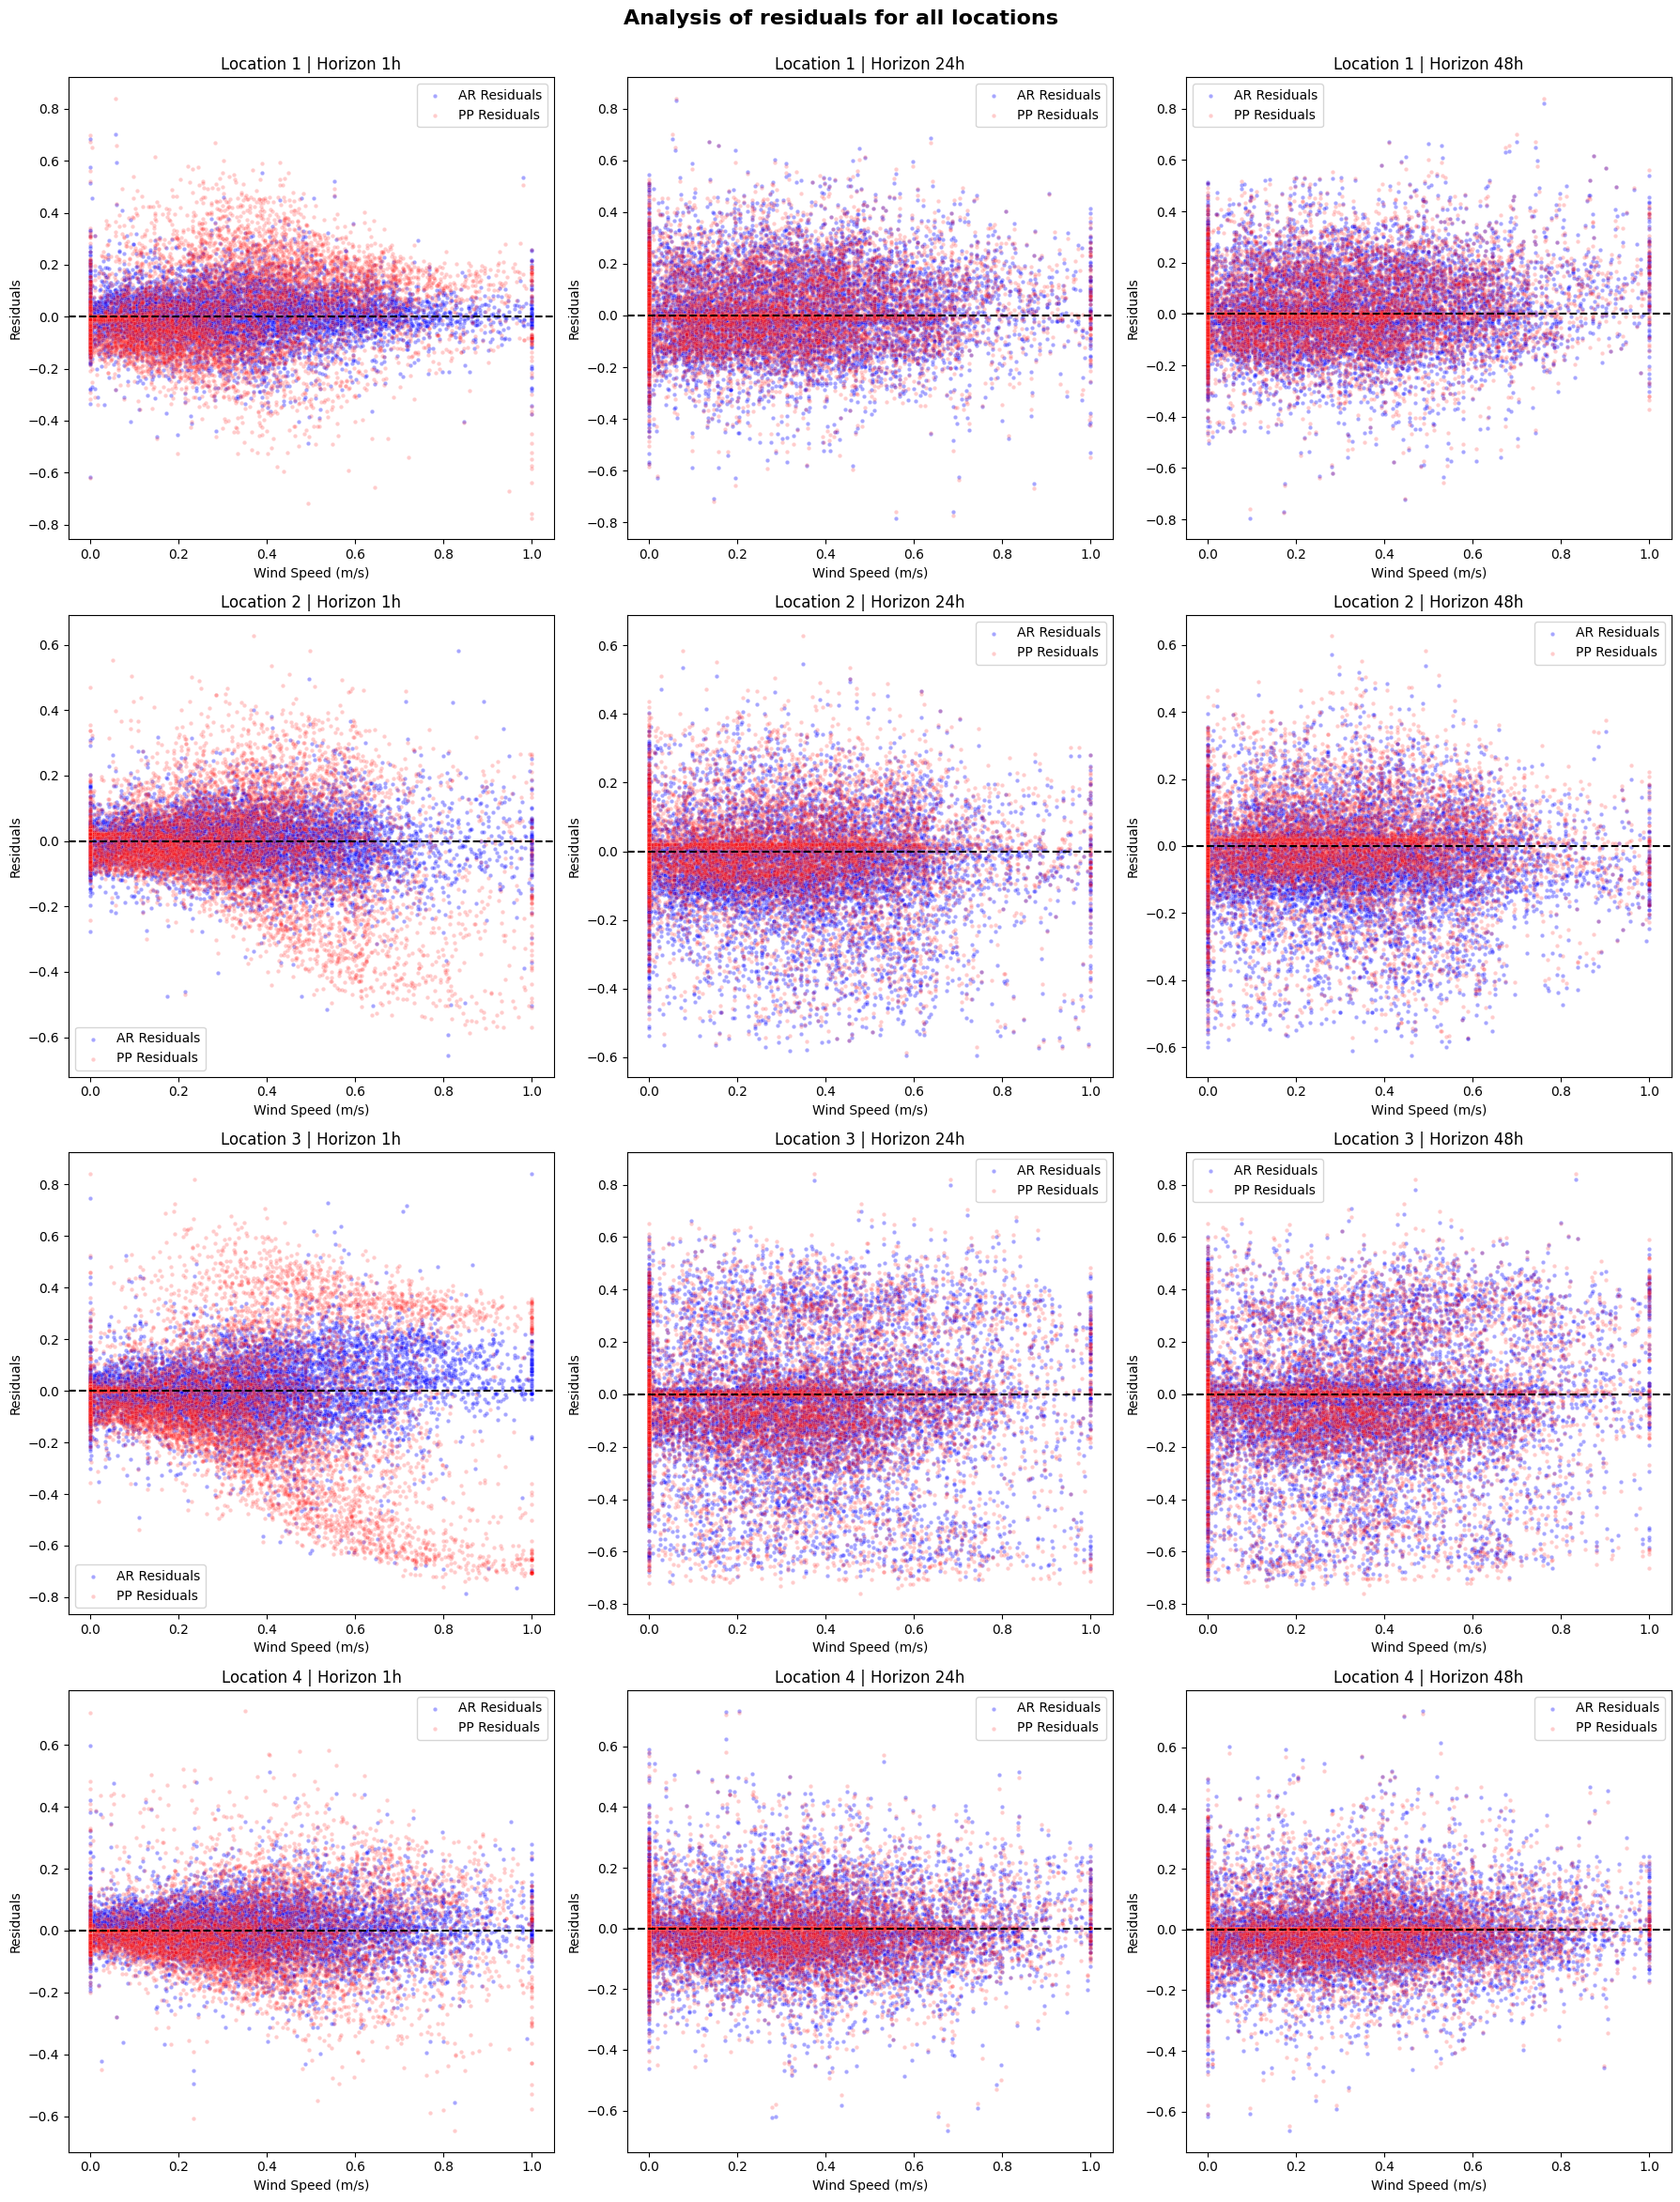

In [79]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(18, 26))
fig.suptitle("Analysis of residuals for all locations", fontsize=16, fontweight='bold', y=0.9)
horizon_to_col = {1: 0, 24: 1, 48: 2}
wind_analysis = pd.DataFrame()
rmse_df = pd.DataFrame()

for loc in range(1, 5):
    df = pd.read_csv(DATASETS_PREPROCESSED_DIR / f"Location_{loc}_test.csv")

    X_pp = df.drop(columns=["time", "p_base", "delta_p"])
    y_pp_all = load(pp_models_dir / f"stacking_model{loc}.pkl").predict(X_pp)

    for horizon in [1, 24, 48]:
        lagged = add_lags(df, horizon)
        # ar_model = load(ar_models_dir / f"stacking_regressor_h{horizon}.pkl")
        ar_model = load(ar_models_dir / f"hybrid_h{horizon}_s10.pkl")

        X_ar = lagged.drop(columns=["time", "delta_p", "target", "p_base", "row_idx"])
        y = lagged["target"].to_numpy()
        y_ar = ar_model.predict(X_ar)
        y_pp = np.asarray(y_pp_all)[lagged["row_idx"].to_numpy() + horizon]  # getting only the predictions corresponding to the lagged rows

        res_ar = y - y_ar
        res_pp = y - y_pp

        rmse_ar = np.sqrt(np.mean(res_ar**2))
        rmse_pp = np.sqrt(np.mean(res_pp**2))

        lagged["wind_bins"] = pd.cut(lagged["wind_speed_100m"], bins=np.arange(0, 1.05, 0.05))  # 1.05 needed to include 1.0 in the last bin
        lagged["residuals_ar"] = res_ar
        lagged["residuals_pp"] = res_pp
        lagged["rmse_ar"] = rmse_ar
        lagged["rmse_pp"] = rmse_pp

        current_errors = lagged.groupby("wind_bins").agg(
            mean_error_ar=("residuals_ar", "mean"),
            mae_ar=("residuals_ar", lambda x: np.mean(np.abs(x))),
            rmse_ar=("residuals_ar", lambda x: np.sqrt(np.mean(x**2))),
            mean_error_pp=("residuals_pp", "mean"),
            mae_pp=("residuals_pp", lambda x: np.mean(np.abs(x))),
            rmse_pp=("residuals_pp", lambda x: np.sqrt(np.mean(x**2))),
            count=("residuals_ar", "count")
        ).reset_index()

        current_errors["location"] = loc
        current_errors["horizon"] = horizon
        wind_analysis = pd.concat([wind_analysis, current_errors], ignore_index=True)

        rmse_df = pd.concat([rmse_df, pd.DataFrame({
            "location": [loc], 
            "horizon": [horizon],
            "rmse_ar": [rmse_ar], 
            "rmse_pp": [rmse_pp]
        })], ignore_index=True)

        row_idx = loc - 1
        col_idx = horizon_to_col[horizon]
        ax = axes[row_idx, col_idx]

        sns.scatterplot(x=lagged["wind_speed_100m"], y=res_ar, alpha=0.35, ax=ax, s=10, color='blue', label='AR Residuals', zorder=1)
        sns.scatterplot(x=lagged["wind_speed_100m"], y=res_pp, alpha=0.20, ax=ax, s=10, color='red', label='PP Residuals', zorder=1)
        ax.axhline(y=0, color="black", linestyle="--")

        ax.set_title(f"Location {loc} | Horizon {horizon}h")
        ax.set_ylabel("Residuals")
        ax.set_xlabel("Wind Speed (m/s)")

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


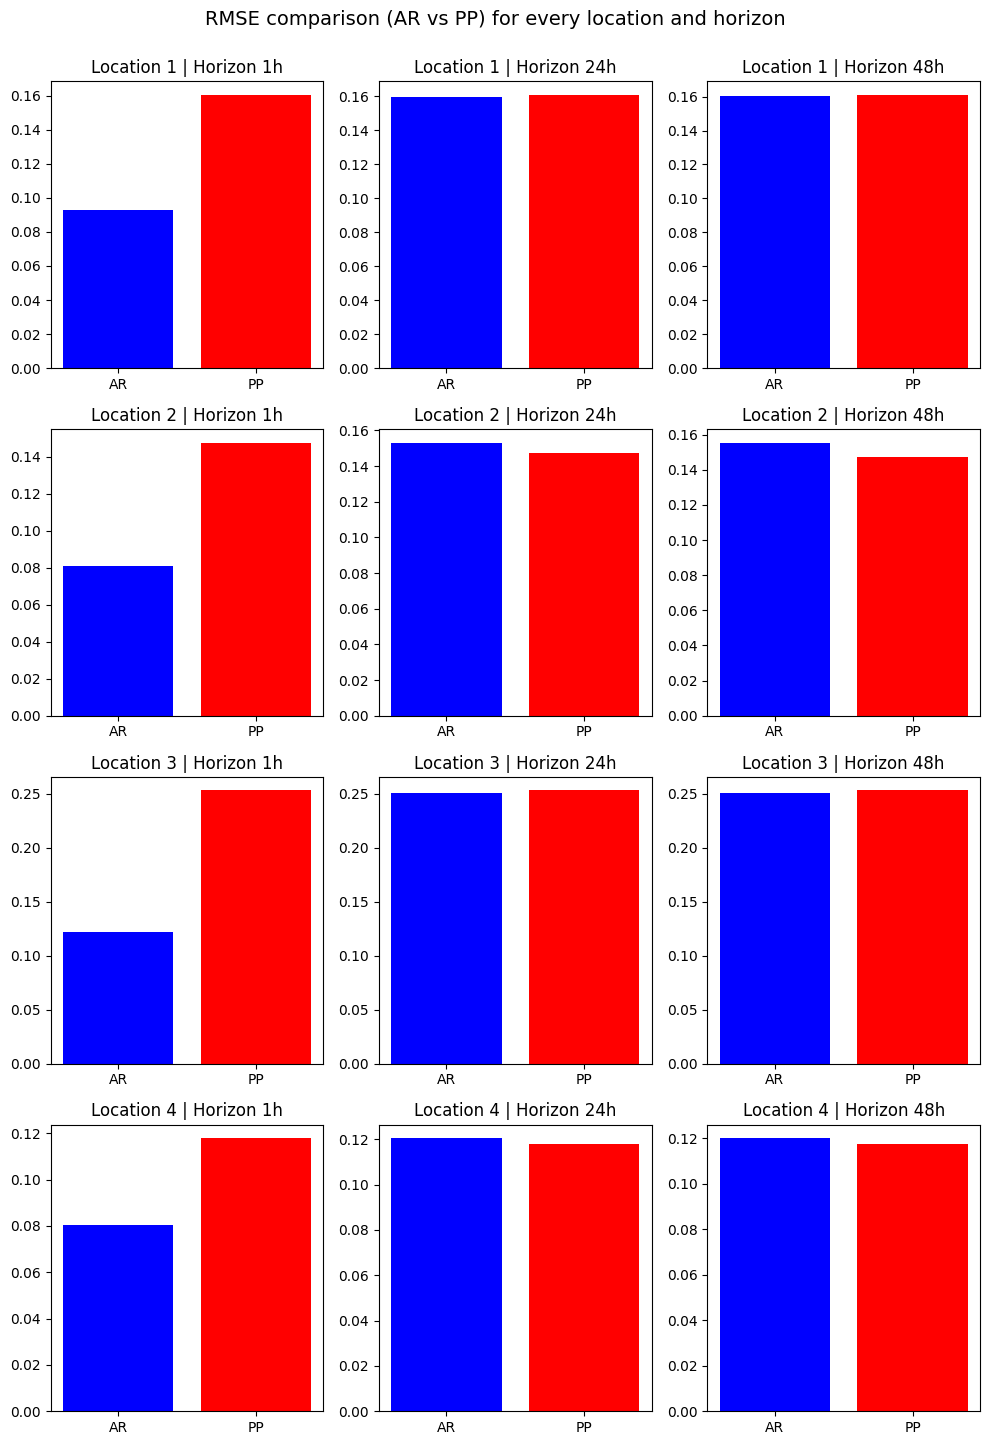

In [80]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(10, 16))

for loc in range(1, 5):
    for horizon in [1, 24, 48]:
        row_idx = loc - 1
        col_idx = horizon_to_col[horizon]
        ax = axes[row_idx, col_idx]

        row = rmse_df[(rmse_df.location == loc) & (rmse_df.horizon == horizon)].iloc[0]
        ax.bar(["AR", "PP"], [row.rmse_ar, row.rmse_pp], color=['blue', 'red'])
        ax.set_title(f"Location {loc} | Horizon {horizon}h")

fig.suptitle("RMSE comparison (AR vs PP) for every location and horizon", fontsize=14, y=0.9)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

In [81]:
pd.set_option('display.max_rows', None) # it should disply all df lines only in this notebook, if it does it globally remove this line
wind_analysis

,wind_bins,mean_error_ar,mae_ar,rmse_ar,mean_error_pp,mae_pp,rmse_pp,count,location,horizon
0,"(0.0, 0.05]",-0.002493,0.061086,0.084388,-0.024062,0.069333,0.103191,411,1,1
1,"(0.05, 0.1]",0.004636,0.061291,0.091488,-0.017485,0.087892,0.125261,581,1,1
2,"(0.1, 0.15]",0.002560,0.061782,0.085229,-0.013956,0.104126,0.138015,666,1,1
3,"(0.15, 0.2]",-0.004610,0.064692,0.086761,-0.019867,0.111507,0.141396,639,1,1
4,"(0.2, 0.25]",0.001076,0.069048,0.091260,-0.004757,0.124980,0.159597,680,1,1
5,"(0.25, 0.3]",0.005599,0.071888,0.096871,0.025746,0.147107,0.186263,680,1,1
6,"(0.3, 0.35]",0.003501,0.081973,0.105858,0.030898,0.161434,0.199662,631,1,1
7,"(0.35, 0.4]",0.002173,0.087760,0.114801,0.054360,0.165590,0.203146,631,1,1
8,"(0.4, 0.45]",0.004446,0.080907,0.108983,0.062573,0.167706,0.205076,560,1,1
9,"(0.45, 0.5]",0.012357,0.077629,0.107680,0.061519,0.158227,0.195852,480,1,1
